<a href="https://colab.research.google.com/github/afranailaarkarna/Prediksi-Status-Kemiskinan-Rumah-Tangga-Audit-Keadilan/blob/main/SDGs_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Latar Belakang

### Hubungan Project dengan SDGs 1: Tanpa Kemiskinan

*Sustainable Development Goals* (SDGs) poin ke-1 bertujuan untuk mengakhiri kemiskinan dalam segala bentuk di mana pun. Kemiskinan tidak hanya soal pendapatan yang rendah, tetapi juga terbatasnya akses terhadap pendidikan, tempat tinggal yang layak, sanitasi, air bersih, listrik, dan kepemilikan aset.

Project ini berfokus pada tiga target SDGs 1:

* **Target 1.2**: mengurangi setidaknya setengah proporsi penduduk yang hidup dalam kemiskinan di segala dimensinya menurut definisi nasional.
* **Target 1.3**: menerapkan sistem dan upaya perlindungan sosial yang tepat bagi semua orang, termasuk kelompok yang paling miskin dan rentan.
* **Target 1.4**: menjamin bahwa semua orang, khususnya masyarakat miskin dan rentan, memiliki hak yang sama atas sumber daya ekonomi dan akses terhadap layanan dasar.

### Permasalahan di Lapangan

Program bantuan sosial hanya efektif jika menjangkau rumah tangga yang tepat. Pendapatan rumah tangga sulit diverifikasi, terutama bagi pekerja sektor informal. Karena itu, banyak negara memakai pendekatan ***Proxy Means Test* (PMT)**, yaitu menebak tingkat kesejahteraan dari ciri-ciri rumah tangga yang mudah diamati, seperti:

* **Kondisi rumah** (jenis bangunan, atap, dinding, luas lantai, umur rumah, jumlah kamar),
* **Akses layanan dasar** (listrik, air bersih, fasilitas toilet),
* **Kepemilikan aset** (televisi, kulkas, mesin cuci, komputer, ponsel, kendaraan),
* **Karakteristik kepala rumah tangga** (usia, status pernikahan, pendidikan, pekerjaan),
* **Komposisi rumah tangga** (jumlah anggota, jumlah anak, jumlah anggota yang bekerja).

Cara PMT konvensional kurang akurat sehingga rumah tangga miskin bisa terlewat (*exclusion error*), sementara rumah tangga yang tidak miskin justru ikut menerima bantuan (*inclusion error*). Selain itu, jika model penargetan lebih sering salah pada kelompok tertentu (misalnya rumah tangga dengan kepala keluarga perempuan atau wilayah tertentu), maka ketidakadilan baru akan muncul.

### Peran Machine Learning

Machine Learning dapat membantu melalui pendekatan **klasifikasi**. Model mempelajari pola dari data survei pendapatan dan pengeluaran keluarga untuk memprediksi apakah suatu rumah tangga termasuk kelompok **miskin** (40% terbawah berdasarkan pendapatan per kapita) atau **tidak miskin**. Ambang 40% terbawah dipakai karena sejalan dengan praktik penargetan perlindungan sosial, misalnya basis data kesejahteraan sosial di Indonesia yang menyasar 40% rumah tangga berpenghasilan terendah.

Model hanya memakai ciri-ciri yang mudah diamati (kondisi rumah, aset, dan komposisi keluarga). **Seluruh kolom pendapatan dan pengeluaran sengaja dibuang** dari fitur agar model tidak "mencontek" jawaban. Hal ini meniru kondisi nyata, yaitu petugas tidak mengetahui pendapatan pasti rumah tangga.

Project ini juga menambahkan **audit keadilan (*fairness audit*)**. Model sengaja dilatih **tanpa** atribut jenis kelamin kepala rumah tangga dan wilayah (region), kemudian hasil prediksinya diperiksa per kelompok. Tujuannya melihat apakah masih ada kesenjangan kemampuan model mengenali rumah tangga miskin antar kelompok.

### Tujuan Project

Project ini membangun sistem **prediksi status kemiskinan rumah tangga** menggunakan dataset *Family Income and Expenditure* (Kaggle) yang bersumber dari survei *Family Income and Expenditure Survey* (FIES) oleh *Philippine Statistics Authority*. Untuk menemukan pendekatan terbaik, project ini membandingkan **2 algoritma klasifikasi**, yaitu Logistic Regression dan Random Forest berdasarkan metrik akurasi, presisi, *recall*, dan F1-score. Model terbaik kemudian diaudit dari sisi keadilan antar jenis kelamin kepala rumah tangga dan antar wilayah.

### Kontribusi terhadap SDGs 1

Dengan model dan audit ini, diharapkan:

1. **Teridentifikasinya rumah tangga miskin** yang perlu diprioritaskan untuk bantuan dan perlindungan sosial (Target 1.2 dan 1.3),
2. **Terlihatnya faktor-faktor yang berkaitan dengan kemiskinan** (kondisi hunian, aset, dan komposisi keluarga) sebagai dasar kebijakan akses layanan dasar (Target 1.4),
3. **Terdeteksinya potensi bias model** sebelum dipakai dalam penargetan bantuan, sehingga teknologi tidak menyisihkan kelompok tertentu.

In [ ]:
import pandas as pd
import numpy as np
import sklearn

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-Learn version:", sklearn.__version__)
print("Environment siap digunakan!")

Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-Learn version: 1.6.1
Environment siap digunakan!


# Project Machine Learning - SDGs 1: Tanpa Kemiskinan
## Prediksi Status Kemiskinan Rumah Tangga dan Audit Keadilan menggunakan Algoritma Klasifikasi

* **Topik SDGs:** Target 1.2 - Mengurangi setidaknya setengah proporsi penduduk yang hidup dalam kemiskinan, serta mendukung Target 1.3 (perlindungan sosial) dan Target 1.4 (akses layanan dasar dan sumber daya ekonomi).
* **Tujuan Project:** Membandingkan 2 algoritma Machine Learning (Logistic Regression & Random Forest) untuk memprediksi status kemiskinan rumah tangga, lalu mengaudit keadilan model terbaik terhadap jenis kelamin kepala rumah tangga dan wilayah.
* **Dataset:** Family Income and Expenditure oleh Francis Paul Flores (Kaggle, data dari Philippine Statistics Authority) - https://www.kaggle.com/datasets/grosvenpaul/family-income-and-expenditure
* **Unit analisis:** satu baris = satu rumah tangga.
* **Fitur:** karakteristik kepala rumah tangga (usia, status pernikahan, pendidikan, pekerjaan), komposisi keluarga, kondisi rumah (bangunan, atap, dinding, luas, umur, kamar, status kepemilikan), akses listrik, air, dan toilet, serta kepemilikan aset (jumlah televisi, kulkas, mesin cuci, komputer, ponsel, kendaraan, dan lain-lain).
* **Atribut sensitif (hanya untuk audit, tidak dipakai untuk melatih model):** jenis kelamin kepala rumah tangga (`household_head_sex`) dan wilayah (`region`).
* **Target:** status kemiskinan. Rumah tangga dengan **pendapatan per kapita di bawah persentil ke-40** diberi kode 1 (Miskin), sisanya kode 0 (Tidak Miskin).

### Import Library

In [1]:
import os
import re
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import joblib

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Semua library berhasil di-import!")

Semua library berhasil di-import!


### Import Data

Unduh dataset dari Kaggle (https://www.kaggle.com/datasets/grosvenpaul/family-income-and-expenditure), lalu letakkan file `Family Income and Expenditure.csv` di folder yang sama dengan notebook ini (atau di salah satu lokasi pada daftar di bawah). Dataset ini bersifat publik, cukup login ke Kaggle lalu klik **Download**.

Alternatif lewat Kaggle CLI: `kaggle datasets download -d grosvenpaul/family-income-and-expenditure --unzip`

In [9]:

import os
import re
import pandas as pd

nama_file = 'Family Income and Expenditure.csv'

if os.path.exists(nama_file):
    df = pd.read_csv(nama_file)
    print("Dataset berhasil dibaca!")
else:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(nama_file)

df.columns = [
    re.sub(r'[^0-9a-zA-Z]+', '_', kolom).strip('_').lower()
    for kolom in df.columns
]

display(df.head())


Saving Family Income and Expenditure.csv to Family Income and Expenditure.csv


,total_household_income,region,total_food_expenditure,main_source_of_income,agricultural_household_indicator,bread_and_cereals_expenditure,total_rice_expenditure,meat_expenditure,total_fish_and_marine_products_expenditure,fruit_expenditure,...,number_of_refrigerator_freezer,number_of_washing_machine,number_of_airconditioner,number_of_car_jeep_van,number_of_landline_wireless_telephones,number_of_cellular_phone,number_of_personal_computer,number_of_stove_with_oven_gas_range,number_of_motorized_banca,number_of_motorcycle_tricycle
0,480332,CAR,117848,Wage/Salaries,0,42140,38300,24676,16806,3325,...,1,1,0,0,0,2,1,0,0,1
1,198235,CAR,67766,Wage/Salaries,0,17329,13008,17434,11073,2035,...,0,1,0,0,0,3,1,0,0,2
2,82785,CAR,61609,Wage/Salaries,1,34182,32001,7783,2590,1730,...,0,0,0,0,0,0,0,0,0,0
3,107589,CAR,78189,Wage/Salaries,0,34030,28659,10914,10812,690,...,0,0,0,0,0,1,0,0,0,0
4,189322,CAR,94625,Wage/Salaries,0,34820,30167,18391,11309,1395,...,1,0,0,0,0,3,0,0,0,1


In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Print Detail Data Mentah

In [11]:
import os
import re
import pandas as pd
from google.colab import files

# Memastikan variabel df terdefinisi jika runtime sempat ter-restart
if 'df' not in globals() or df is None:
    nama_file = 'Family Income and Expenditure.csv'
    kandidat_path = [
        nama_file,
        f'data/{nama_file}',
        f'../data/{nama_file}',
        f'/kaggle/input/family-income-and-expenditure/{nama_file}',
    ]
    for path in kandidat_path:
        if os.path.exists(path):
            df = pd.read_csv(path)
            df.columns = [re.sub(r'[^0-9a-zA-Z]+', '_', c).strip('_').lower() for c in df.columns]
            print(f"Dataset berhasil dimuat ulang secara otomatis dari: {path}")
            break

if 'df' in globals() and df is not None:
    print(f"Jumlah Baris: {df.shape[0]}")
    print(f"Jumlah Kolom: {df.shape[1]}")
    print("\n--- Tipe Data dan Informasi Non-Null ---")
    df.info()
else:
    print("Error: Dataset tidak ditemukan. Pastikan Anda sudah mengunduh dataset dan menjalakan sel impor data terlebih dahulu.")

Jumlah Baris: 41544
Jumlah Kolom: 60

--- Tipe Data dan Informasi Non-Null ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41544 entries, 0 to 41543
Data columns (total 60 columns):
 #   Column                                        Non-Null Count  Dtype 
---  ------                                        --------------  ----- 
 0   total_household_income                        41544 non-null  int64 
 1   region                                        41544 non-null  object
 2   total_food_expenditure                        41544 non-null  int64 
 3   main_source_of_income                         41544 non-null  object
 4   agricultural_household_indicator              41544 non-null  int64 
 5   bread_and_cereals_expenditure                 41544 non-null  int64 
 6   total_rice_expenditure                        41544 non-null  int64 
 7   meat_expenditure                              41544 non-null  int64 
 8   total_fish_and_marine_products_expenditure    41544 non-null  int64

### Print Deskripsi Kolom

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
total_household_income,41544.0,247555.584802,286880.522653,11285.0,104895.00,164079.5,291138.50,11815988.0
total_food_expenditure,41544.0,85099.158194,51637.947682,2947.0,51017.25,72985.5,105635.50,827565.0
agricultural_household_indicator,41544.0,0.429858,0.676666,0.0,0.00,0.0,1.00,2.0
bread_and_cereals_expenditure,41544.0,25133.723642,13466.482984,0.0,16556.00,23324.0,31439.00,765864.0
total_rice_expenditure,41544.0,18195.825005,11727.224350,0.0,11020.00,16620.0,23920.00,758326.0
meat_expenditure,41544.0,10540.072574,10497.727757,0.0,3353.75,7332.5,14292.00,261566.0
total_fish_and_marine_products_expenditure,41544.0,10529.318337,7812.201613,0.0,5504.00,8695.0,13388.00,188208.0
fruit_expenditure,41544.0,2550.474990,2969.752879,0.0,1024.75,1820.0,3100.00,273769.0
vegetables_expenditure,41544.0,5006.918568,3300.175236,0.0,2873.00,4314.0,6304.25,74800.0
restaurant_and_hotels_expenditure,41544.0,15436.566075,23705.195929,0.0,1930.00,7314.0,19921.25,725296.0


### Pembersihan Data

Pada dataset ini, nilai yang hilang terutama muncul pada kolom pekerjaan kepala rumah tangga (`household_head_occupation` dan `household_head_class_of_worker`). Nilai tersebut **tidak dihapus**, melainkan diganti dengan kategori `Unknown`. Alasannya, kepala rumah tangga yang tidak memiliki data pekerjaan sering kali justru tidak bekerja, yaitu kelompok yang rentan secara ekonomi. Jika barisnya dihapus, kelompok yang paling relevan dengan SDGs 1 akan ikut hilang dari analisis.

In [13]:
# Hapus spasi berlebih pada kolom teks
kolom_teks = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for kolom in kolom_teks:
    df[kolom] = df[kolom].str.strip()

jumlah_kosong = df.isnull().sum()
print("--- Jumlah Missing Value per Kolom (sebelum ditangani) ---")
print(jumlah_kosong[jumlah_kosong > 0])

# Kolom teks yang kosong -> 'Unknown', kolom angka yang kosong -> median
for kolom in df.columns:
    if kolom in kolom_teks:
        df[kolom] = df[kolom].fillna('Unknown')
    elif df[kolom].isnull().any():
        df[kolom] = df[kolom].fillna(df[kolom].median())

print("\n--- Jumlah Missing Value per Kolom (setelah ditangani) ---")
print("Total missing value:", int(df.isnull().sum().sum()))

jumlah_duplikat = df.duplicated().sum()
print(f"\nJumlah data duplikat: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Data duplikat dihapus. Jumlah baris sekarang: {df.shape[0]}")
else:
    print("Tidak ada data duplikat, data siap diproses.")

--- Jumlah Missing Value per Kolom (sebelum ditangani) ---
household_head_occupation         7536
household_head_class_of_worker    7536
toilet_facilities                 1580
dtype: int64

--- Jumlah Missing Value per Kolom (setelah ditangani) ---
Total missing value: 0

Jumlah data duplikat: 0
Tidak ada data duplikat, data siap diproses.


### Pembentukan Label Kemiskinan dan Kolom Bantu

Dataset ini tidak memiliki kolom status kemiskinan, sehingga label dibuat dari pendapatan:

1. Hitung **pendapatan per kapita** = `total_household_income` dibagi `total_number_of_family_members`. Kemiskinan diukur per orang, karena pendapatan yang sama akan terasa berbeda bagi keluarga 2 orang dan keluarga 8 orang.
2. Tentukan ambang pada **persentil ke-40**. Rumah tangga dengan pendapatan per kapita di bawah ambang diberi label **Miskin (1)**, sisanya **Tidak Miskin (0)**.

Kolom-kolom bantu di bawah ini akan **dibuang kembali** sebelum pemodelan agar tidak terjadi kebocoran target.

In [14]:
kol_pendapatan = 'total_household_income'
kol_anggota    = 'total_number_of_family_members'
kol_bekerja    = 'total_number_of_family_members_employed'
kol_sex        = 'household_head_sex'
kol_region     = 'region'

for kolom in [kol_pendapatan, kol_anggota, kol_sex, kol_region]:
    assert kolom in df.columns, f"Kolom '{kolom}' tidak ditemukan. Cek daftar kolom di atas."

df['pendapatan_per_kapita'] = df[kol_pendapatan] / df[kol_anggota].clip(lower=1)

PERSENTIL_MISKIN = 0.40
ambang_miskin = df['pendapatan_per_kapita'].quantile(PERSENTIL_MISKIN)

df['miskin'] = (df['pendapatan_per_kapita'] < ambang_miskin).astype(int)
df['status'] = np.where(df['miskin'] == 1, 'Miskin', 'Tidak Miskin')
df['jk_kepala'] = df[kol_sex]
df['wilayah'] = df[kol_region]

print(f"Ambang pendapatan per kapita (persentil ke-{int(PERSENTIL_MISKIN*100)}): {ambang_miskin:,.0f}")
df[['pendapatan_per_kapita', 'miskin', 'status', 'jk_kepala', 'wilayah']].head()

Ambang pendapatan per kapita (persentil ke-40): 32,991


,pendapatan_per_kapita,miskin,status,jk_kepala,wilayah
0,120083.000000,0,Tidak Miskin,Female,CAR
1,66078.333333,0,Tidak Miskin,Male,CAR
2,13797.500000,1,Miskin,Male,CAR
3,35863.000000,0,Tidak Miskin,Male,CAR
4,47330.500000,0,Tidak Miskin,Male,CAR


### Pengambilan Sampel (Opsional)

Dataset berisi puluhan ribu rumah tangga. Algoritma SVM dan KNN bekerja lambat pada data sebesar itu, sehingga diambil sampel acak sebanyak `JUMLAH_SAMPEL` rumah tangga. Ambang kemiskinan dihitung **sebelum** sampel diambil, jadi definisi miskin tetap berdasarkan seluruh data. Ubah nilainya menjadi `None` jika ingin memakai seluruh data (proses training akan lebih lama).

In [15]:
JUMLAH_SAMPEL = 15000   # ubah menjadi None untuk memakai seluruh data

if JUMLAH_SAMPEL is not None and len(df) > JUMLAH_SAMPEL:
    df = df.sample(n=JUMLAH_SAMPEL, random_state=42).reset_index(drop=True)

print(f"Jumlah rumah tangga yang dipakai: {df.shape[0]}")
print(f"Persentase miskin pada data yang dipakai: {df['miskin'].mean() * 100:.2f}%")

Jumlah rumah tangga yang dipakai: 15000
Persentase miskin pada data yang dipakai: 39.98%


### Buat Visualisasi Data berdasarkan Jumlah Sampel per Status Kemiskinan

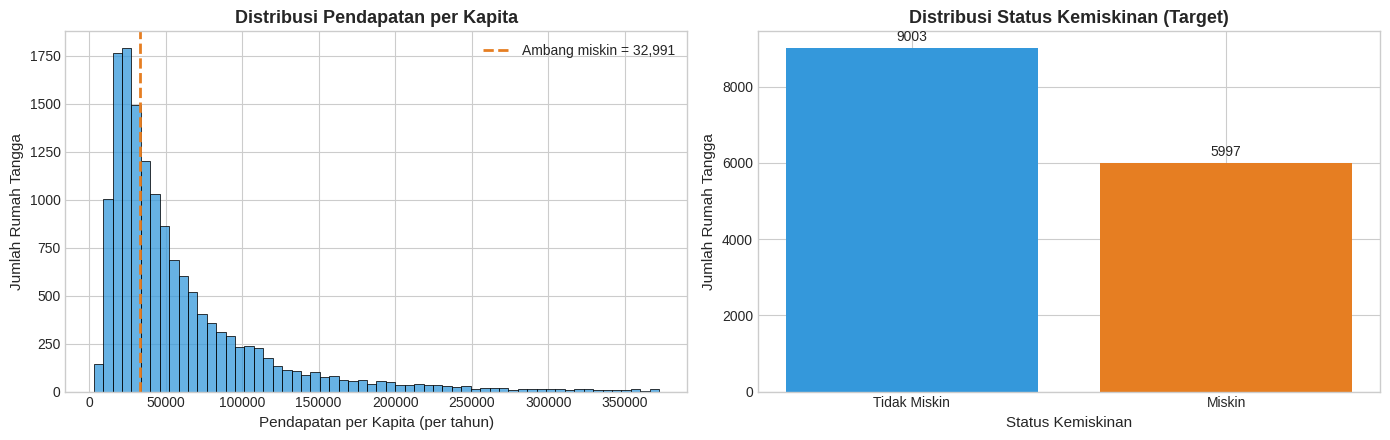

status
Tidak Miskin    60.02 %
Miskin          39.98 %
Name: proportion, dtype: object


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Distribusi pendapatan per kapita dan garis ambang kemiskinan
batas = df['pendapatan_per_kapita'].quantile(0.99)
sns.histplot(df.loc[df['pendapatan_per_kapita'] <= batas, 'pendapatan_per_kapita'], bins=60, color='#3498db', ax=axes[0])
axes[0].axvline(ambang_miskin, color='#e67e22', linestyle='--', linewidth=2, label=f'Ambang miskin = {ambang_miskin:,.0f}')
axes[0].set_title('Distribusi Pendapatan per Kapita', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Pendapatan per Kapita (per tahun)', fontsize=11)
axes[0].set_ylabel('Jumlah Rumah Tangga', fontsize=11)
axes[0].legend()

# Jumlah sampel per status kemiskinan
hitung_status = df['status'].value_counts().reindex(['Tidak Miskin', 'Miskin'])
bars = axes[1].bar(hitung_status.index, hitung_status.values, color=['#3498db', '#e67e22'])
axes[1].set_title('Distribusi Status Kemiskinan (Target)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Status Kemiskinan', fontsize=11)
axes[1].set_ylabel('Jumlah Rumah Tangga', fontsize=11)
for b in bars:
    axes[1].annotate(f'{int(b.get_height())}', (b.get_x() + b.get_width() / 2., b.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

print((df['status'].value_counts(normalize=True) * 100).round(2).astype(str) + ' %')

### Buat Visualisasi Kesenjangan Kemiskinan berdasarkan Jenis Kelamin Kepala Rumah Tangga, Wilayah, dan Ukuran Keluarga

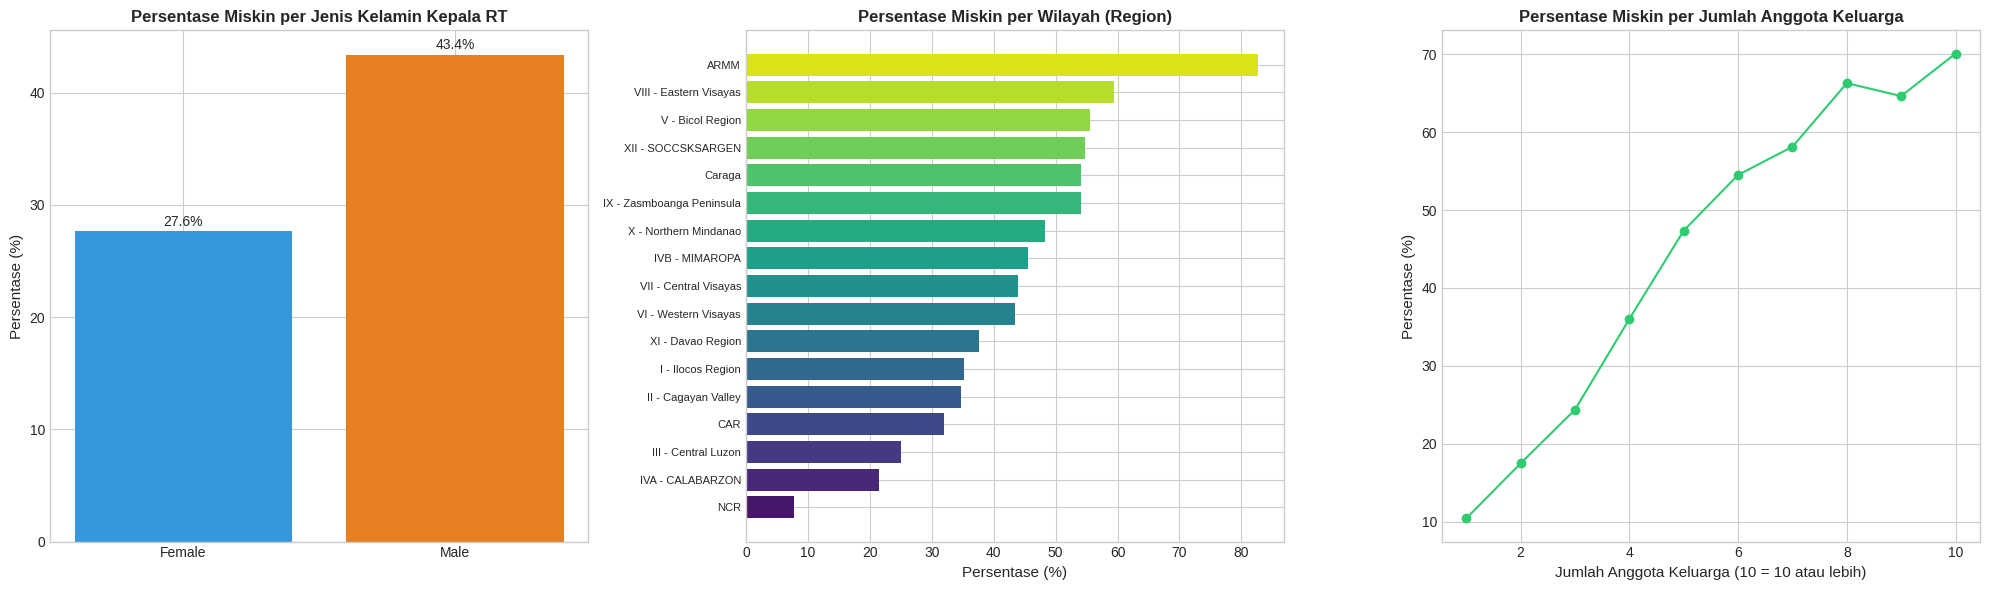

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Berdasarkan jenis kelamin kepala rumah tangga
rate_jk = df.groupby('jk_kepala')['miskin'].mean().sort_values() * 100
axes[0].bar(rate_jk.index, rate_jk.values, color=['#3498db', '#e67e22'][:len(rate_jk)])
axes[0].set_title('Persentase Miskin per Jenis Kelamin Kepala RT', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Persentase (%)', fontsize=11)
for i, v in enumerate(rate_jk.values):
    axes[0].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)

# 2. Berdasarkan wilayah
rate_wil = df.groupby('wilayah')['miskin'].mean().sort_values() * 100
axes[1].barh(rate_wil.index, rate_wil.values, color=sns.color_palette('viridis', len(rate_wil)))
axes[1].set_title('Persentase Miskin per Wilayah (Region)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Persentase (%)', fontsize=11)
axes[1].tick_params(axis='y', labelsize=8)

# 3. Berdasarkan jumlah anggota keluarga
anggota = df[kol_anggota].clip(upper=10)
rate_ang = df.groupby(anggota)['miskin'].mean() * 100
axes[2].plot(rate_ang.index, rate_ang.values, marker='o', color='#2ecc71')
axes[2].set_title('Persentase Miskin per Jumlah Anggota Keluarga', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Jumlah Anggota Keluarga (10 = 10 atau lebih)', fontsize=11)
axes[2].set_ylabel('Persentase (%)', fontsize=11)

plt.tight_layout()
plt.show()

### Buat Visualisasi Data Numerik (Usia Kepala RT, Jumlah Anggota Keluarga, dan Luas Lantai Rumah)

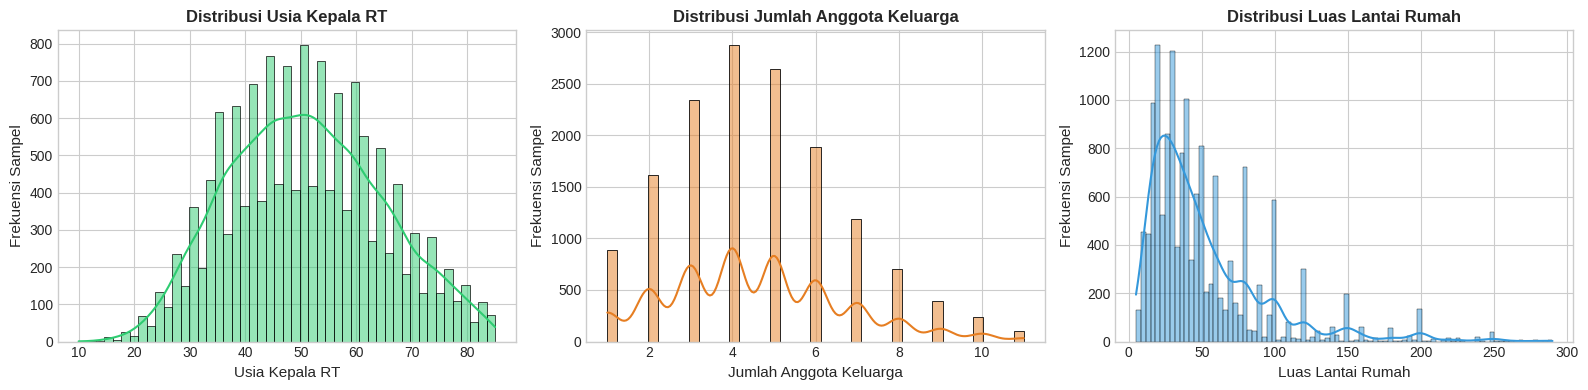

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
warna = ['#2ecc71', '#e67e22', '#3498db']
numerik = [('household_head_age', 'Usia Kepala RT'), (kol_anggota, 'Jumlah Anggota Keluarga'), ('house_floor_area', 'Luas Lantai Rumah')]
numerik = [(k, j) for k, j in numerik if k in df.columns]

for ax, (kolom, judul), c in zip(axes, numerik, warna):
    data_plot = df[kolom][df[kolom] <= df[kolom].quantile(0.99)]   # buang 1% nilai ekstrem agar grafik terbaca
    sns.histplot(x=data_plot, kde=True, color=c, ax=ax)
    ax.set_title(f'Distribusi {judul}', fontsize=12, fontweight='bold')
    ax.set_xlabel(judul, fontsize=11)
    ax.set_ylabel('Frekuensi Sampel', fontsize=11)

plt.tight_layout()
plt.show()

### Buat Visualisasi Kepemilikan Aset, Kondisi Dinding Rumah, dan Rata-rata Fitur per Kelompok

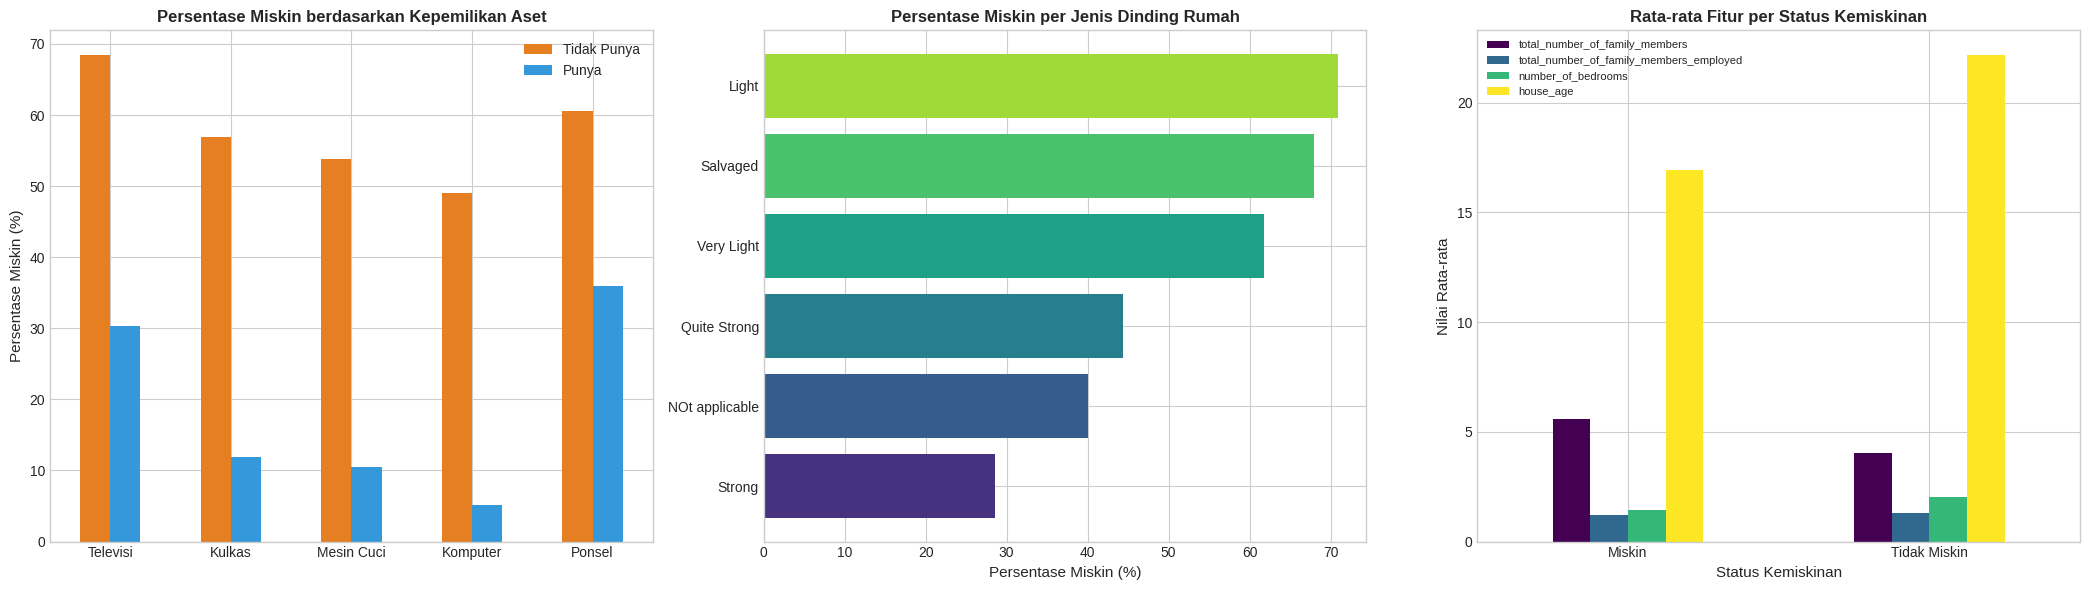

In [19]:
def cari(*kata_kunci):
    """Cari nama kolom pertama yang mengandung semua kata kunci."""
    for c in df.columns:
        if all(k in c for k in kata_kunci):
            return c
    return None

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Persentase miskin berdasarkan kepemilikan aset
aset = {'television': 'Televisi', 'refrigerator': 'Kulkas', 'washing_machine': 'Mesin Cuci',
        'personal_computer': 'Komputer', 'cellular': 'Ponsel'}
baris = []
for kunci, nama in aset.items():
    kolom = cari('number_of', kunci)
    if kolom is not None:
        baris.append({
            'Aset': nama,
            'Tidak Punya': df.loc[df[kolom] == 0, 'miskin'].mean() * 100,
            'Punya': df.loc[df[kolom] > 0, 'miskin'].mean() * 100,
        })
pd.DataFrame(baris).set_index('Aset').plot(kind='bar', ax=axes[0], color=['#e67e22', '#3498db'], rot=0)
axes[0].set_title('Persentase Miskin berdasarkan Kepemilikan Aset', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Persentase Miskin (%)', fontsize=11)
axes[0].set_xlabel('')

# 2. Persentase miskin berdasarkan jenis dinding rumah
if 'type_of_walls' in df.columns:
    rate_dinding = (df.groupby('type_of_walls')['miskin'].mean() * 100).sort_values()
    axes[1].barh(rate_dinding.index, rate_dinding.values, color=sns.color_palette('viridis', len(rate_dinding)))
    axes[1].set_title('Persentase Miskin per Jenis Dinding Rumah', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Persentase Miskin (%)', fontsize=11)

# 3. Rata-rata fitur per kelompok
kolom_rata = [c for c in [kol_anggota, kol_bekerja, 'number_of_bedrooms', 'house_age'] if c in df.columns]
rata = df.groupby('status')[kolom_rata].mean()
rata.plot(kind='bar', ax=axes[2], colormap='viridis', rot=0)
axes[2].set_title('Rata-rata Fitur per Status Kemiskinan', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Status Kemiskinan', fontsize=11)
axes[2].set_ylabel('Nilai Rata-rata', fontsize=11)
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Buat Visualisasi Korelasi Antar Fitur Numerik

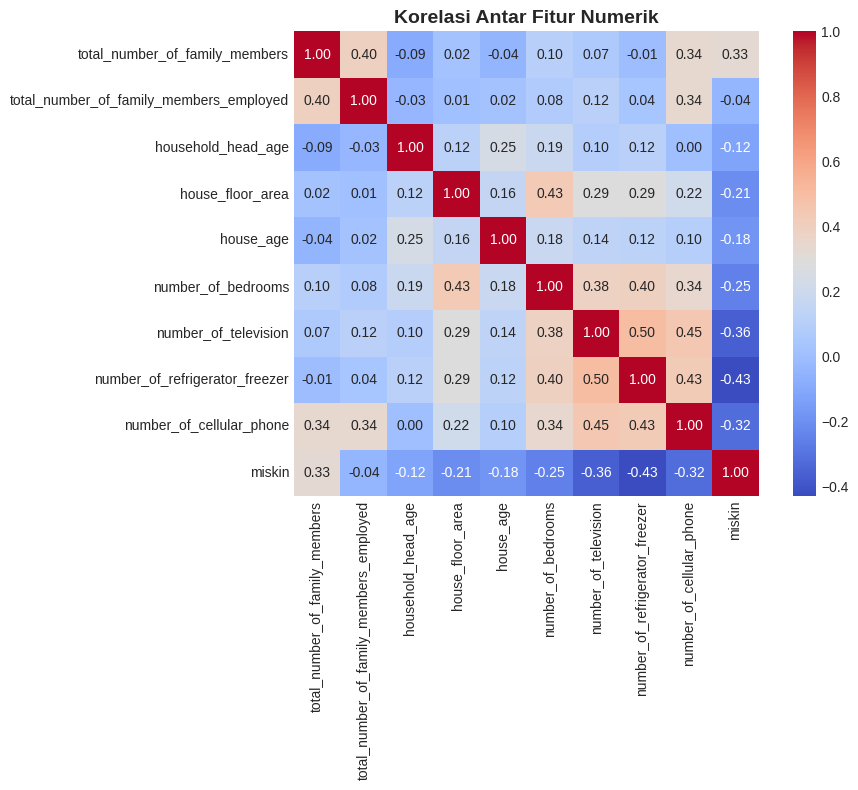

In [20]:
kolom_numerik = [kol_anggota, kol_bekerja, 'household_head_age', 'house_floor_area', 'house_age', 'number_of_bedrooms',
                 cari('number_of', 'television'), cari('number_of', 'refrigerator'), cari('number_of', 'cellular'), 'miskin']
kolom_numerik = [c for c in kolom_numerik if c is not None and c in df.columns]

plt.figure(figsize=(10, 8))
sns.heatmap(df[kolom_numerik].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Korelasi Antar Fitur Numerik', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Persiapan Fitur dan Atribut Sensitif

Beberapa keputusan penting pada tahap ini:

* **Semua kolom pendapatan dan pengeluaran dibuang** (nama kolom yang mengandung `income`, `expenditure`, atau `expenses`, serta `imputed_house_rental_value`). Kolom-kolom ini adalah bahan pembentuk label sehingga jika dipakai, model hanya "menghitung ulang" label dan hasilnya tidak bermakna (kebocoran target).
* Kolom `pendapatan_per_kapita`, `status`, dan kolom bantu lain dibuang kembali. Hanya kolom `miskin` yang dipertahankan sebagai target.
* Kolom `household_head_sex` dan `region` **tidak dipakai sebagai fitur**. Keduanya disimpan terpisah (`sensitif`) khusus untuk audit keadilan.
* Kolom `agricultural_household_indicator` berisi kode kategori (angka), sehingga diperlakukan sebagai kategori.

In [21]:
# Simpan atribut sensitif secara terpisah untuk audit keadilan
sensitif = df[['jk_kepala', 'wilayah']].copy()

# Buang kolom bantu, atribut sensitif, dan semua kolom pendapatan/pengeluaran
kolom_bantu = ['pendapatan_per_kapita', 'status', 'jk_kepala', 'wilayah', kol_sex, kol_region]
kolom_moneter = [c for c in df.columns
                 if any(k in c for k in ['income', 'expenditure', 'expenses', 'rental_value'])]

df_model = df.drop(columns=kolom_bantu + kolom_moneter, errors='ignore')

# Kode kategori berbentuk angka -> teks
if 'agricultural_household_indicator' in df_model.columns:
    df_model['agricultural_household_indicator'] = df_model['agricultural_household_indicator'].astype(str)

print("Kolom moneter yang dibuang :", kolom_moneter)
print(f"\nJumlah fitur yang dipakai untuk pemodelan: {df_model.shape[1] - 1}")
print("Daftar fitur:", [c for c in df_model.columns if c != 'miskin'])

Kolom moneter yang dibuang : ['total_household_income', 'total_food_expenditure', 'main_source_of_income', 'bread_and_cereals_expenditure', 'total_rice_expenditure', 'meat_expenditure', 'total_fish_and_marine_products_expenditure', 'fruit_expenditure', 'vegetables_expenditure', 'restaurant_and_hotels_expenditure', 'alcoholic_beverages_expenditure', 'tobacco_expenditure', 'clothing_footwear_and_other_wear_expenditure', 'housing_and_water_expenditure', 'imputed_house_rental_value', 'medical_care_expenditure', 'transportation_expenditure', 'communication_expenditure', 'education_expenditure', 'miscellaneous_goods_and_services_expenditure', 'special_occasions_expenditure', 'crop_farming_and_gardening_expenses', 'total_income_from_entrepreneurial_acitivites']

Jumlah fitur yang dipakai untuk pemodelan: 35
Daftar fitur: ['agricultural_household_indicator', 'household_head_age', 'household_head_marital_status', 'household_head_highest_grade_completed', 'household_head_job_or_business_indicato

### Encoding Target agar menjadi numerikal

In [22]:
nama_kelas = {0: 'Tidak Miskin', 1: 'Miskin'}
kelas = [nama_kelas[0], nama_kelas[1]]

# Simpan salinan fitur mentah (sebelum encoding) untuk keperluan inferensi
fitur_mentah = df_model.drop(columns=['miskin']).copy()

print(f"Bentuk dataset: {df_model.shape}")
print("\n--- Pemetaan Label ---")
for kode, nama in nama_kelas.items():
    print(f"{kode:>2} = {nama}")

df_model.head()

Bentuk dataset: (15000, 36)

--- Pemetaan Label ---
 0 = Tidak Miskin
 1 = Miskin


,agricultural_household_indicator,household_head_age,household_head_marital_status,household_head_highest_grade_completed,household_head_job_or_business_indicator,household_head_occupation,household_head_class_of_worker,type_of_household,total_number_of_family_members,members_with_age_less_than_5_year_old,...,number_of_washing_machine,number_of_airconditioner,number_of_car_jeep_van,number_of_landline_wireless_telephones,number_of_cellular_phone,number_of_personal_computer,number_of_stove_with_oven_gas_range,number_of_motorized_banca,number_of_motorcycle_tricycle,miskin
0,0,61,Married,Teacher Training and Education Sciences Programs,No Job/Business,Unknown,Unknown,Single Family,2,0,...,1,0,0,0,2,0,0,0,0,0
1,2,33,Married,Teacher Training and Education Sciences Programs,With Job/Business,Receptionists and information clerks,Worked for private establishment,Extended Family,4,0,...,1,0,0,1,2,1,0,0,0,0
2,0,62,Married,High School Graduate,No Job/Business,Unknown,Unknown,Extended Family,4,0,...,1,0,0,0,1,0,0,0,0,0
3,1,51,Married,Grade 3,With Job/Business,General managers/managing proprietors in agric...,Self-employed wihout any employee,Single Family,7,1,...,1,0,0,0,1,0,0,0,0,1
4,1,55,Single,Grade 3,With Job/Business,Farmhands and laborers,Worked for private establishment,Single Family,1,0,...,0,0,0,0,0,0,0,0,0,1


### Encoding Fitur Kategorikal

Fitur kategorikal (misalnya status pernikahan, pendidikan, pekerjaan, jenis atap, dan jenis dinding) diubah menjadi kolom numerik dengan *one-hot encoding* agar dapat diproses oleh algoritma.

Beberapa kolom (misalnya pendidikan dan pekerjaan) memiliki puluhan kategori, dan banyak di antaranya sangat jarang muncul. Kategori yang frekuensinya **di bawah 1%** digabung menjadi kategori `Lainnya` agar jumlah kolom tidak membengkak dan model tidak menghafal kategori langka.

In [23]:
df_encoded = df_model.copy()

fitur_awal = df_encoded.drop(columns=['miskin'])
kolom_kategorikal = [c for c in fitur_awal.columns if not pd.api.types.is_numeric_dtype(fitur_awal[c])]
print("Kolom kategorikal:", kolom_kategorikal)

# Gabungkan kategori langka (< 1%) menjadi 'Lainnya'
kategori_umum = {}
for kolom in kolom_kategorikal:
    frekuensi = df_encoded[kolom].value_counts(normalize=True)
    kategori_umum[kolom] = frekuensi[frekuensi >= 0.01].index.tolist()
    df_encoded[kolom] = df_encoded[kolom].where(df_encoded[kolom].isin(kategori_umum[kolom]), 'Lainnya')

df_encoded = pd.get_dummies(df_encoded, columns=kolom_kategorikal, dtype=int)

print("\nBentuk dataset sebelum one-hot encoding:", df_model.shape)
print("Bentuk dataset setelah one-hot encoding:", df_encoded.shape)
df_encoded.head()

Kolom kategorikal: ['agricultural_household_indicator', 'household_head_marital_status', 'household_head_highest_grade_completed', 'household_head_job_or_business_indicator', 'household_head_occupation', 'household_head_class_of_worker', 'type_of_household', 'type_of_building_house', 'type_of_roof', 'type_of_walls', 'tenure_status', 'toilet_facilities', 'main_source_of_water_supply']

Bentuk dataset sebelum one-hot encoding: (15000, 36)
Bentuk dataset setelah one-hot encoding: (15000, 124)


,household_head_age,total_number_of_family_members,members_with_age_less_than_5_year_old,members_with_age_5_17_years_old,total_number_of_family_members_employed,house_floor_area,house_age,number_of_bedrooms,electricity,number_of_television,...,main_source_of_water_supply_Lainnya,"main_source_of_water_supply_Lake, river, rain and others","main_source_of_water_supply_Own use, faucet, community water system","main_source_of_water_supply_Own use, tubed/piped deep well",main_source_of_water_supply_Peddler,"main_source_of_water_supply_Protected spring, river, stream, etc","main_source_of_water_supply_Shared, faucet, community water system","main_source_of_water_supply_Shared, tubed/piped deep well",main_source_of_water_supply_Tubed/piped shallow well,"main_source_of_water_supply_Unprotected spring, river, stream, etc"
0,61,2,0,0,0,60,30,4,1,1,...,0,0,0,1,0,0,0,0,0,0
1,33,4,0,2,2,40,20,2,1,1,...,0,0,1,0,0,0,0,0,0,0
2,62,4,0,2,0,71,35,3,1,1,...,0,0,1,0,0,0,0,0,0,0
3,51,7,1,4,1,20,20,2,1,1,...,0,0,0,0,0,1,0,0,0,0
4,55,1,0,0,1,50,5,1,0,0,...,0,0,0,0,0,0,1,0,0,0


### Memisahkan Data Fitur dengan Target

In [24]:
X = df_encoded.drop(columns=['miskin'])

y = df_encoded['miskin']

print("Ukuran Fitur (X):", X.shape)
print("Ukuran Target (y):", y.shape)

Ukuran Fitur (X): (15000, 123)
Ukuran Target (y): (15000,)


### Split Data untuk Training dan Testing

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah Data Latih (X_train): {X_train.shape[0]} baris")
print(f"Jumlah Data Uji (X_test)  : {X_test.shape[0]} baris")
print(f"Persentase miskin pada data latih: {y_train.mean() * 100:.2f}%")
print(f"Persentase miskin pada data uji  : {y_test.mean() * 100:.2f}%")

Jumlah Data Latih (X_train): 12000 baris
Jumlah Data Uji (X_test)  : 3000 baris
Persentase miskin pada data latih: 39.98%
Persentase miskin pada data uji  : 39.97%


### Lakukan Standarisasi

In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling berhasil dilakukan!")

Feature scaling berhasil dilakukan!


### Latih Model

Proses training SVM dan KNN dapat memakan waktu beberapa menit tergantung jumlah sampel dan spesifikasi komputer.

In [27]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

predictions = {}

print("--- Memulai Proses Training Model ---")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    print(f"Model [{name}] selesai dilatih!")

--- Memulai Proses Training Model ---
Model [Logistic Regression] selesai dilatih!
Model [Random Forest] selesai dilatih!


### Print hasil Evaluasi

Selain akurasi, ditambahkan kolom **Recall (Miskin)** dan **F1 (Miskin)** yang khusus mengukur kemampuan model mengenali rumah tangga miskin. *Recall* kelompok miskin penting karena rumah tangga miskin yang terlewat (*exclusion error*) adalah kesalahan yang paling merugikan pada program bantuan. Model terbaik dipilih berdasarkan **F1 (Miskin)**, yaitu keseimbangan antara rumah tangga miskin yang berhasil dikenali (*recall*) dan ketepatan prediksi miskin (*precision*).

In [28]:
results_list = []

for name, y_pred in predictions.items():
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    rec_pos = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1_pos = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

    results_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Recall (Miskin)': rec_pos,
        'F1 (Miskin)': f1_pos
    })

df_results = pd.DataFrame(results_list)
df_results = df_results.sort_values(by='F1 (Miskin)', ascending=False).reset_index(drop=True)

print("--- HASIL PERBANDINGAN 6 MODEL MACHINE LEARNING ---")
df_results

--- HASIL PERBANDINGAN 6 MODEL MACHINE LEARNING ---


,Model,Accuracy,Precision,Recall,F1-Score,Recall (Miskin),F1 (Miskin)
0,Logistic Regression,0.855667,0.855126,0.855667,0.855247,0.803169,0.816448
1,Random Forest,0.853667,0.853043,0.853667,0.852797,0.785655,0.811020


### Buat Visualisasi Perbandingan Performa Model

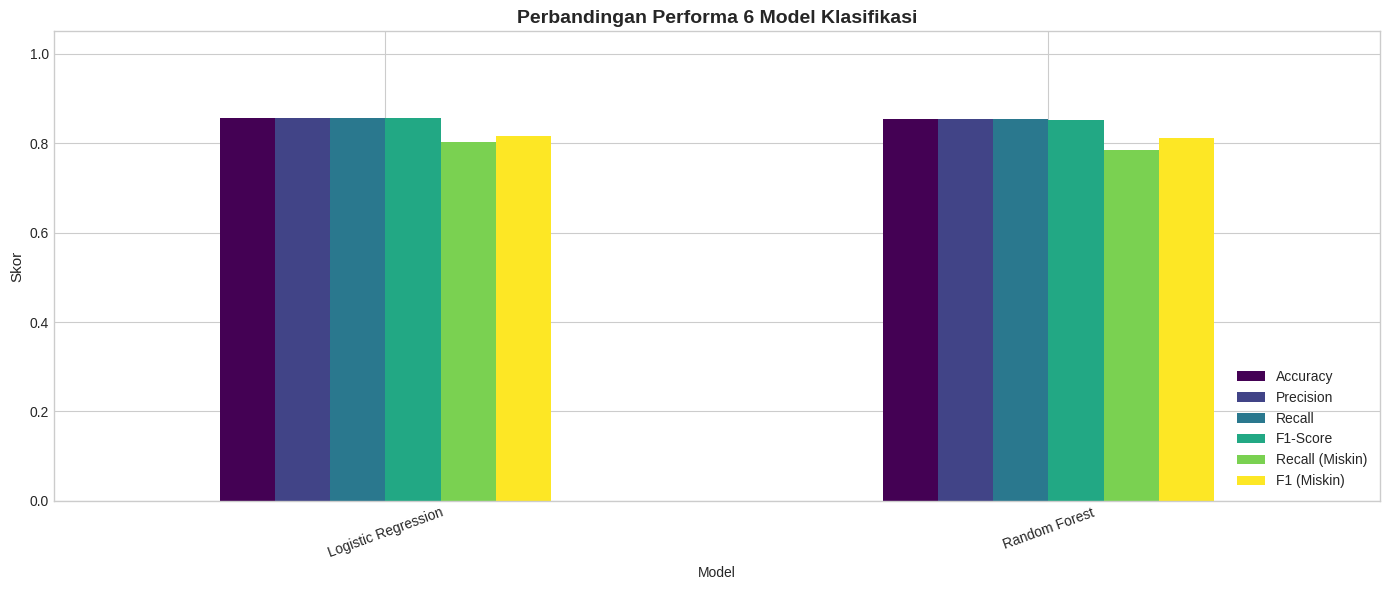

In [29]:
df_plot = df_results.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Recall (Miskin)', 'F1 (Miskin)']]

ax = df_plot.plot(kind='bar', figsize=(14, 6), colormap='viridis', rot=20)
ax.set_title('Perbandingan Performa 6 Model Klasifikasi', fontsize=14, fontweight='bold')
ax.set_ylabel('Skor', fontsize=11)
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Buat Confusion Matrix dari model dengan F1 (Miskin) tertinggi

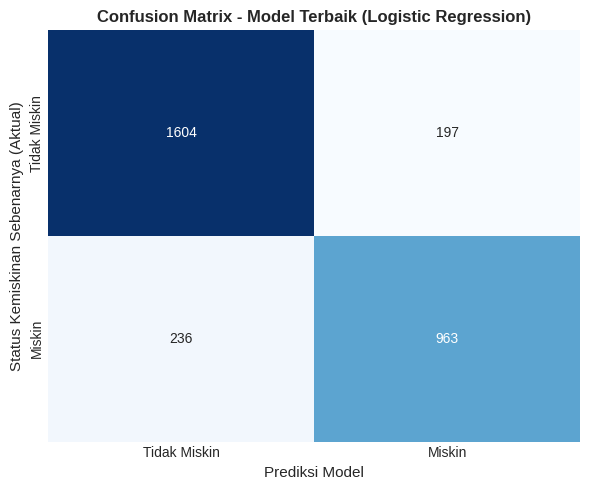


Model Terbaik berdasarkan F1 (Miskin): Logistic Regression

--- Classification Report ---
              precision    recall  f1-score   support

Tidak Miskin       0.87      0.89      0.88      1801
      Miskin       0.83      0.80      0.82      1199

    accuracy                           0.86      3000
   macro avg       0.85      0.85      0.85      3000
weighted avg       0.86      0.86      0.86      3000



In [30]:
best_model_name = df_results.iloc[0]['Model']
best_pred = predictions[best_model_name]

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=kelas,
            yticklabels=kelas)

plt.title(f'Confusion Matrix - Model Terbaik ({best_model_name})', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Status Kemiskinan Sebenarnya (Aktual)', fontsize=11)
plt.tight_layout()
plt.show()

print(f"\nModel Terbaik berdasarkan F1 (Miskin): {best_model_name}")
print("\n--- Classification Report ---")
print(classification_report(y_test, best_pred, target_names=kelas, zero_division=0))

### Audit Keadilan (*Fairness Audit*) Model Terbaik

Bagian ini adalah inti keterkaitan project dengan SDGs 1 dari sisi keadilan. Model terbaik diperiksa pada data uji untuk setiap kelompok jenis kelamin kepala rumah tangga dan setiap wilayah (*region*), dengan tiga ukuran:

* **Tingkat miskin aktual**: persentase rumah tangga di kelompok itu yang sebenarnya miskin.
* **Tingkat prediksi miskin** (*selection rate*): persentase rumah tangga di kelompok itu yang diprediksi model miskin.
* **True Positive Rate (TPR)**: dari rumah tangga yang benar-benar miskin, berapa persen yang berhasil dikenali model. TPR rendah berarti banyak rumah tangga miskin yang terlewat (*exclusion error*).

Selisih terbesar antar kelompok pada tingkat prediksi disebut *demographic parity difference*, dan pada TPR disebut *equal opportunity difference*. Semakin mendekati 0, semakin adil model antar kelompok. Pada konteks penargetan bantuan, selisih TPR paling penting karena menunjukkan kelompok mana yang lebih sering terlewat dari program.

In [31]:
def audit_kelompok(kolom_sensitif):
    data = pd.DataFrame({
        'kelompok': sensitif.loc[X_test.index, kolom_sensitif].values,
        'aktual': y_test.values,
        'prediksi': best_pred
    })

    baris = []
    for kelompok, g in data.groupby('kelompok'):
        positif_aktual = g[g['aktual'] == 1]
        baris.append({
            'Kelompok': kelompok,
            'Jumlah Sampel': len(g),
            'Aktual Miskin (%)': g['aktual'].mean() * 100,
            'Prediksi Miskin (%)': g['prediksi'].mean() * 100,
            'TPR (%)': (positif_aktual['prediksi'].mean() * 100) if len(positif_aktual) > 0 else np.nan,
        })
    return pd.DataFrame(baris).sort_values('Jumlah Sampel', ascending=False).reset_index(drop=True)

audit_jk = audit_kelompok('jk_kepala')
audit_wilayah = audit_kelompok('wilayah')

pd.set_option('display.max_rows', 50)
print("=== AUDIT BERDASARKAN JENIS KELAMIN KEPALA RUMAH TANGGA ===")
display(audit_jk.round(2))

print("\n=== AUDIT BERDASARKAN WILAYAH (REGION) ===")
display(audit_wilayah.round(2))

=== AUDIT BERDASARKAN JENIS KELAMIN KEPALA RUMAH TANGGA ===


,Kelompok,Jumlah Sampel,Aktual Miskin (%),Prediksi Miskin (%),TPR (%)
0,Male,2375,43.12,42.99,83.01
1,Female,625,28.00,22.24,64.57



=== AUDIT BERDASARKAN WILAYAH (REGION) ===


,Kelompok,Jumlah Sampel,Aktual Miskin (%),Prediksi Miskin (%),TPR (%)
0,NCR,318,8.18,9.75,69.23
1,IVA - CALABARZON,314,22.93,24.52,79.17
2,III - Central Luzon,226,27.88,23.89,61.90
3,VI - Western Visayas,219,46.58,51.60,90.20
4,VII - Central Visayas,188,38.30,35.11,80.56
5,V - Bicol Region,179,55.31,55.87,85.86
6,ARMM,174,87.93,85.63,93.46
7,XI - Davao Region,171,33.92,33.33,68.97
8,I - Ilocos Region,162,35.80,25.93,60.34
9,II - Cagayan Valley,159,32.08,32.70,78.43


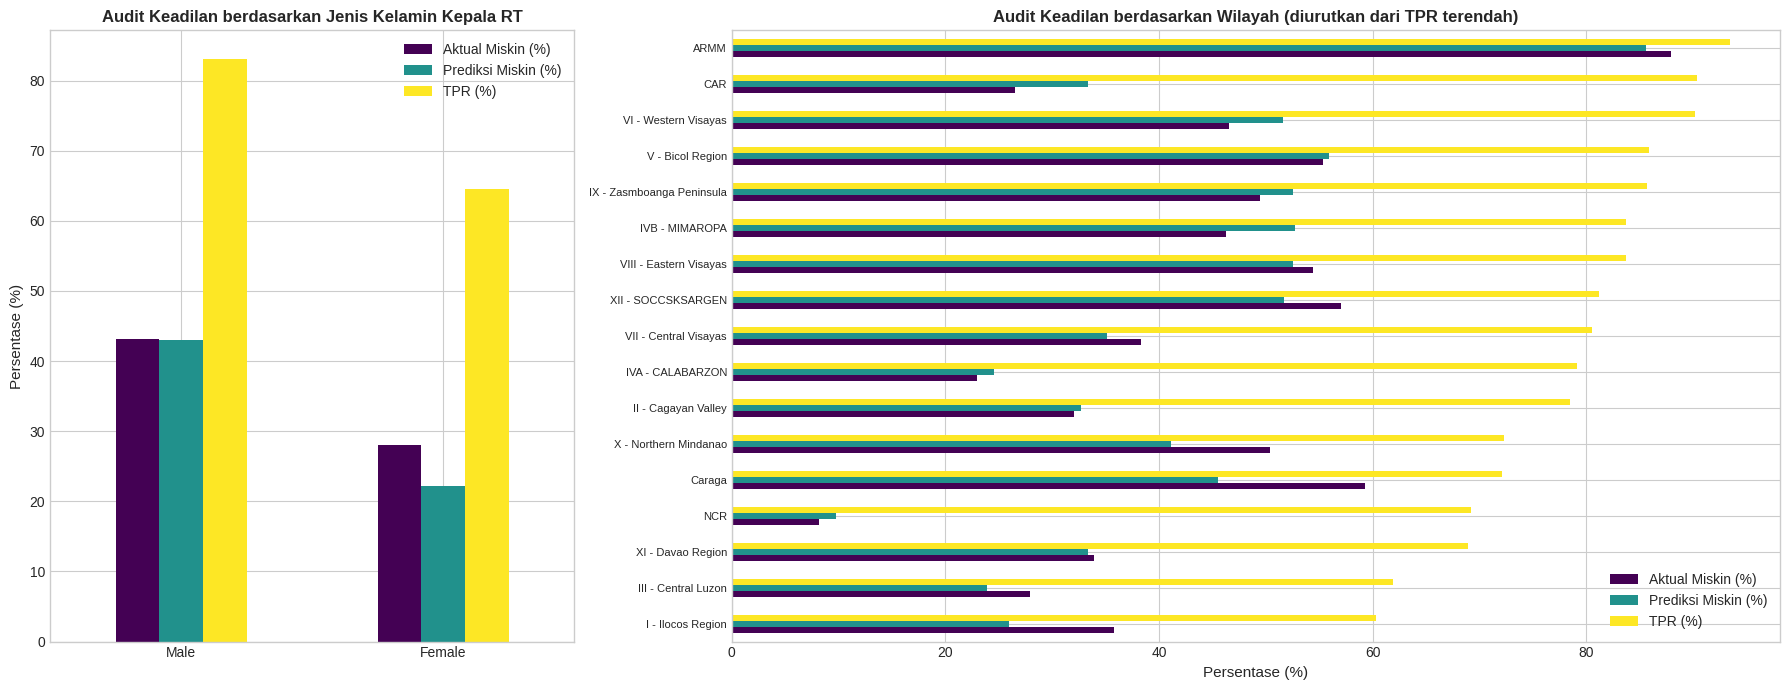

[Jenis Kelamin Kepala RT] Demographic parity difference : 20.75 poin persentase
[Jenis Kelamin Kepala RT] Equal opportunity difference  : 18.44 poin persentase
[Wilayah] Demographic parity difference : 75.88 poin persentase
[Wilayah] Equal opportunity difference  : 33.12 poin persentase

Wilayah dengan TPR terendah (paling banyak rumah tangga miskin terlewat): I - Ilocos Region
Catatan: wilayah dengan jumlah sampel uji kecil memiliki angka yang kurang stabil.


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1, 2]})

plot_jk = audit_jk.set_index('Kelompok')[['Aktual Miskin (%)', 'Prediksi Miskin (%)', 'TPR (%)']]
plot_jk.plot(kind='bar', ax=axes[0], colormap='viridis', rot=0)
axes[0].set_title('Audit Keadilan berdasarkan Jenis Kelamin Kepala RT', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Persentase (%)', fontsize=11)
axes[0].set_xlabel('')

plot_wil = audit_wilayah.sort_values('TPR (%)').set_index('Kelompok')[['Aktual Miskin (%)', 'Prediksi Miskin (%)', 'TPR (%)']]
plot_wil.plot(kind='barh', ax=axes[1], colormap='viridis')
axes[1].set_title('Audit Keadilan berdasarkan Wilayah (diurutkan dari TPR terendah)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Persentase (%)', fontsize=11)
axes[1].set_ylabel('')
axes[1].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.show()

# Ringkasan selisih antar kelompok
def ringkas_gap(audit, nama):
    dpd = audit['Prediksi Miskin (%)'].max() - audit['Prediksi Miskin (%)'].min()
    eod = audit['TPR (%)'].max() - audit['TPR (%)'].min()
    print(f"[{nama}] Demographic parity difference : {dpd:.2f} poin persentase")
    print(f"[{nama}] Equal opportunity difference  : {eod:.2f} poin persentase")
    return dpd, eod

gap_jk = ringkas_gap(audit_jk, 'Jenis Kelamin Kepala RT')
gap_wilayah = ringkas_gap(audit_wilayah, 'Wilayah')

kelompok_tpr_terendah = audit_wilayah.loc[audit_wilayah['TPR (%)'].idxmin(), 'Kelompok']
print(f"\nWilayah dengan TPR terendah (paling banyak rumah tangga miskin terlewat): {kelompok_tpr_terendah}")
print("Catatan: wilayah dengan jumlah sampel uji kecil memiliki angka yang kurang stabil.")

### Inferensi

In [33]:
best_model = models[best_model_name]
idx_miskin = 1

def siapkan_fitur(data_mentah):
    """Ubah data rumah tangga mentah menjadi format yang sama dengan data latih."""
    d = data_mentah.copy()
    for kolom in kolom_kategorikal:
        d[kolom] = d[kolom].astype(str)
        d[kolom] = d[kolom].where(d[kolom].isin(kategori_umum[kolom]), 'Lainnya')
    d = pd.get_dummies(d, columns=kolom_kategorikal, dtype=int)
    return d.reindex(columns=X.columns, fill_value=0)

def prediksi_rumah_tangga(data_mentah):
    d_scaled = scaler.transform(siapkan_fitur(data_mentah))
    return best_model.predict(d_scaled)[0], best_model.predict_proba(d_scaled)[0]

# Simulasi 1: ambil satu sampel dari data uji
sample = X_test.iloc[[0]]
sample_scaled = scaler.transform(sample)

prediksi_hasil = best_model.predict(sample_scaled)[0]
probabilitas = best_model.predict_proba(sample_scaled)[0]

print("=== HASIL SIMULASI PREDIKSI STATUS KEMISKINAN (SAMPEL DATA UJI) ===")
print(f"Status Aktual              : {nama_kelas[int(y_test.iloc[0])]}")
print(f"PREDIKSI                   : {nama_kelas[int(prediksi_hasil)]}")
print(f"Peluang Rumah Tangga Miskin: {probabilitas[idx_miskin] * 100:.2f}%")

=== HASIL SIMULASI PREDIKSI STATUS KEMISKINAN (SAMPEL DATA UJI) ===
Status Aktual              : Tidak Miskin
PREDIKSI                   : Tidak Miskin
Peluang Rumah Tangga Miskin: 13.22%


**Simulasi 2: rumah tangga baru.** Profil dasar dibuat dari nilai yang paling umum (modus untuk kolom kategori, median untuk kolom angka) pada data latih. Kemudian dibuat satu skenario "rumah tangga rentan" dengan mengubah beberapa nilai angka: anggota keluarga banyak, hanya satu yang bekerja, rumah kecil, dan tidak memiliki aset. Ubah nilai pada `skenario_rentan` untuk mencoba kombinasi lain.

In [34]:
# Profil dasar: modus (kategori) dan median (angka)
profil = {}
for kolom in fitur_mentah.columns:
    if kolom in kolom_kategorikal:
        profil[kolom] = fitur_mentah[kolom].mode()[0]
    else:
        profil[kolom] = fitur_mentah[kolom].median()
profil_tipikal = pd.DataFrame([profil])

# Skenario rumah tangga rentan: ubah beberapa kolom angka
skenario_rentan = {
    kol_anggota: 8,
    kol_bekerja: 1,
    'number_of_bedrooms': 1,
    'house_floor_area': 15,
}
for kolom in fitur_mentah.columns:
    if kolom.startswith('number_of_') and kolom != 'number_of_bedrooms':   # jumlah aset = 0
        skenario_rentan[kolom] = 0

profil_rentan = profil_tipikal.copy()
for kolom, nilai in skenario_rentan.items():
    if kolom in profil_rentan.columns:
        profil_rentan[kolom] = nilai

for nama, data_rt in [('RUMAH TANGGA TIPIKAL', profil_tipikal), ('RUMAH TANGGA RENTAN (SKENARIO)', profil_rentan)]:
    pred, prob = prediksi_rumah_tangga(data_rt)
    print(f"=== HASIL SIMULASI: {nama} ===")
    print(f"PREDIKSI : {nama_kelas[int(pred)]}")
    for kode, nama_k in nama_kelas.items():
        print(f"  Peluang {nama_k:<12}: {prob[kode] * 100:.2f}%")
    if pred == 1:
        print("Rekomendasi: dapat dipertimbangkan untuk program bantuan sosial, akses pendidikan, "
              "perbaikan hunian, atau layanan dasar (air bersih dan sanitasi).\n")
    else:
        print("Rekomendasi: diprediksi tidak termasuk kelompok miskin, namun tetap dapat dipantau "
              "jika memiliki faktor kerentanan.\n")

=== HASIL SIMULASI: RUMAH TANGGA TIPIKAL ===
PREDIKSI : Tidak Miskin
  Peluang Tidak Miskin: 70.43%
  Peluang Miskin      : 29.57%
Rekomendasi: diprediksi tidak termasuk kelompok miskin, namun tetap dapat dipantau jika memiliki faktor kerentanan.

=== HASIL SIMULASI: RUMAH TANGGA RENTAN (SKENARIO) ===
PREDIKSI : Miskin
  Peluang Tidak Miskin: 6.61%
  Peluang Miskin      : 93.39%
Rekomendasi: dapat dipertimbangkan untuk program bantuan sosial, akses pendidikan, perbaikan hunian, atau layanan dasar (air bersih dan sanitasi).



### Simpan Model ke Folder

In [35]:
try:
    os.makedirs('../models', exist_ok=True)
    folder_model = '../models'
except OSError:
    os.makedirs('models', exist_ok=True)
    folder_model = 'models'

joblib.dump(best_model, f'{folder_model}/poverty_classification_model.pkl')
joblib.dump(scaler, f'{folder_model}/scaler.pkl')
joblib.dump(nama_kelas, f'{folder_model}/label_mapping.pkl')
joblib.dump(X.columns.tolist(), f'{folder_model}/feature_columns.pkl')
joblib.dump({'kolom_kategorikal': kolom_kategorikal, 'kategori_umum': kategori_umum,
             'ambang_miskin_per_kapita': float(ambang_miskin)}, f'{folder_model}/preprocessing_info.pkl')

print(f"Model, Scaler, Pemetaan Label, Daftar Fitur, dan Info Preprocessing berhasil disimpan ke folder '{folder_model}/'!")

Model, Scaler, Pemetaan Label, Daftar Fitur, dan Info Preprocessing berhasil disimpan ke folder '../models/'!


### Ringkasan Hasil

In [36]:
baris_terbaik = df_results.iloc[0]

print("=== RINGKASAN HASIL PROJECT ===")
print(f"Model terbaik         : {best_model_name}")
print(f"Accuracy              : {baris_terbaik['Accuracy'] * 100:.2f}%")
print(f"F1-Score (terbobot)   : {baris_terbaik['F1-Score'] * 100:.2f}%")
print(f"Recall kelompok miskin: {baris_terbaik['Recall (Miskin)'] * 100:.2f}%")
print(f"F1 kelompok miskin    : {baris_terbaik['F1 (Miskin)'] * 100:.2f}%")
print()
print(f"Selisih prediksi antar jenis kelamin : {gap_jk[0]:.2f} poin persentase")
print(f"Selisih TPR antar jenis kelamin      : {gap_jk[1]:.2f} poin persentase")
print(f"Selisih prediksi antar wilayah       : {gap_wilayah[0]:.2f} poin persentase")
print(f"Selisih TPR antar wilayah            : {gap_wilayah[1]:.2f} poin persentase")

=== RINGKASAN HASIL PROJECT ===
Model terbaik         : Logistic Regression
Accuracy              : 85.57%
F1-Score (terbobot)   : 85.52%
Recall kelompok miskin: 80.32%
F1 kelompok miskin    : 81.64%

Selisih prediksi antar jenis kelamin : 20.75 poin persentase
Selisih TPR antar jenis kelamin      : 18.44 poin persentase
Selisih prediksi antar wilayah       : 75.88 poin persentase
Selisih TPR antar wilayah            : 33.12 poin persentase


## Kesimpulan dan Keterbatasan

**Kesimpulan**

1. Dua algoritma klasifikasi berhasil dibandingkan, dan model terbaik dipilih berdasarkan F1 kelompok miskin karena tujuan utamanya adalah mengenali rumah tangga miskin agar tidak terlewat dari program bantuan (Target 1.2 dan 1.3).
2. Eksplorasi data memperlihatkan bahwa ukuran keluarga, jumlah anggota yang bekerja, kepemilikan aset, dan kondisi rumah berkaitan dengan status kemiskinan, serta terdapat perbedaan tingkat kemiskinan antar wilayah dan jenis kelamin kepala rumah tangga pada data mentah (Target 1.4). Angka pastinya dapat dilihat pada grafik hasil eksplorasi.
3. Walaupun jenis kelamin kepala rumah tangga dan wilayah tidak dipakai sebagai fitur, kemampuan model mengenali rumah tangga miskin masih dapat berbeda antar kelompok (lihat angka pada audit keadilan). Penyebab yang umum adalah fitur lain (misalnya jenis pekerjaan, kondisi rumah, dan kepemilikan aset) yang berfungsi sebagai *proxy* dari wilayah atau jenis kelamin, sehingga membuang kolom sensitif saja belum cukup untuk menjamin keadilan.
4. Model dapat dimanfaatkan sebagai alat bantu untuk menentukan rumah tangga yang perlu diprioritaskan dalam program bantuan dan perlindungan sosial, dengan catatan hasilnya diverifikasi di lapangan.

**Keterbatasan**

* Dataset berasal dari survei rumah tangga di Filipina, sehingga distribusinya belum tentu mencerminkan kondisi Indonesia atau kondisi terkini.
* Definisi miskin pada project ini adalah **40% terbawah berdasarkan pendapatan per kapita (kemiskinan relatif)**, bukan garis kemiskinan resmi. Jika ambang diubah, hasil model juga akan berubah.
* Sebagian data pada project ini hanya berupa sampel acak dari seluruh rumah tangga agar proses training lebih cepat.
* Model menemukan **hubungan (korelasi)**, bukan **sebab-akibat**. Misalnya, memiliki mesin cuci bukan penyebab seseorang tidak miskin.
* Wilayah dengan jumlah sampel uji kecil menghasilkan metrik audit yang kurang stabil.
* Model hanya boleh dipakai sebagai **alat bantu**, bukan satu-satunya dasar keputusan yang menentukan hak atau akses seseorang terhadap bantuan.

**Pengembangan Selanjutnya**

* Menerapkan teknik mitigasi bias, misalnya pembobotan sampel atau penyesuaian *threshold* per wilayah atau per kelompok.
* Mencoba ambang kemiskinan yang berbeda (misalnya 20% atau 30% terbawah) dan algoritma *gradient boosting* seperti LightGBM atau XGBoost.
* Menggunakan data survei sosial ekonomi Indonesia (misalnya SUSENAS) agar lebih relevan dengan konteks lokal.
* Membuat antarmuka sederhana (misalnya dengan Streamlit) agar model mudah dicoba oleh pengguna non-teknis.